# 03: The rulebook

The rulebook gives the agent two things to work with:

- **a checklist** (`rulebook/checklist.yaml`) that says which rules a listing must
  meet, depending on what the product is, and which article of which law each rule
  comes from;
- **a searchable rulebook**: nine law texts, cleaned, cut into small pieces
  ("chunks") that keep their article numbers, and stored in Postgres with a keyword
  index and an embedding for each piece. Every search result comes with a citation
  such as "GPSR Art. 19" and a link to the official text.

This notebook looks at the result:

1. the checklist
2. from web page to clean articles
3. the chunks
4. three ways to search: keywords, meaning, and both
5. how good each method is on 31 test questions
6. the agent's own login, which can read the rulebook but not change it

Built with `uv run python -m listingaudit.rulebook.build`.

In [1]:
# Quiet the model loading: no progress bars, no notes about checking for updates.
# This has to happen before the libraries are imported, so it gets a cell of its own.
import os
import warnings

os.environ.setdefault("TQDM_DISABLE", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import psycopg
from huggingface_hub.utils import logging as hub_logging

from listingaudit.db import connect, connect_as_agent
from listingaudit.rulebook.build import load_articles
from listingaudit.rulebook.checklist import load_checklist
from listingaudit.rulebook.download import raw_file
from listingaudit.rulebook.embed import get_embedder
from listingaudit.rulebook.evaluate import first_right_rank, load_questions, run, scores
from listingaudit.rulebook.search import keyword_search, meaning_search, search
from listingaudit.rulebook.sources import SOURCES, SOURCES_BY_ID

pd.set_option("display.max_colwidth", 110)
hub_logging.set_verbosity_error()
conn = connect()
embedder = get_embedder()  # loads the model from data/models, a few seconds


def sql(query: str, *params) -> pd.DataFrame:
    cursor = conn.execute(query, params)
    return pd.DataFrame(cursor.fetchall(), columns=[c.name for c in cursor.description])


def hits_table(hits) -> pd.DataFrame:
    rows = [(h.citation, round(h.score, 3), h.text[:90]) for h in hits]
    return pd.DataFrame(rows, columns=["citation", "score", "starts with"])


# Chart colours, checked for colour-blind readers: blue, orange, aqua
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, SECONDARY, MUTED, SURFACE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": SECONDARY,
        "axes.titlecolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 1,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 9,
        "axes.titlesize": 10,
    }
)

## 1. The checklist: which rules a listing must meet

Each rule has a plain-language summary, the checks to make, the cases that look wrong
but are fine, the listing fields that hold the evidence, and the law it comes from.
Which rules apply depends on the kind of product. Working out the kind is part of the
agent's job: a curtain rod sold in the curtain category is not a textile.

In [3]:
checklist = load_checklist()
pd.DataFrame(
    [
        {
            "product kind": kind,
            "description": spec.description,
            "extra rules": ", ".join(spec.rules) or "-",
        }
        for kind, spec in checklist.product_kinds.items()
    ]
)

,product kind,description,extra rules
0,textile,"Made mainly of textile fibres, such as rugs, cushions, bed sheets and curtains.",fibre_composition
1,not_textile,"Sold in a textile category but not made of fibres, such as curtain rods and hooks.",-
2,light_bulb,"A light source sold on its own, such as an LED bulb.","safety_warnings, energy_label"
3,lamp,"A lamp or light fitting, with or without a bulb.",safety_warnings
4,unit_price,"Sold by weight or volume, such as coffee, shampoo or cleaning liquid.",unit_price
5,mixed_set,"A set of different products, such as a gift box of shampoo and lotion.",-
6,candle,"A candle, sold by the piece.",safety_warnings
7,general,"Anything else, such as furniture, shoes and decoration.",-


Some rules depend on the listing rather than the product: the 30-day price rule only
applies when the listing announces a price reduction, and the "responsible person in
the EU" only when the manufacturer is outside the EU. Two examples:

In [4]:
rug = checklist.rules_for("textile", "RUG", announces_reduction=True, maker_in_eu=False)
coffee = checklist.rules_for("unit_price", "COFFEE", announces_reduction=False, maker_in_eu=False)
print("A rug on sale, made in China:", [rule.value for rule in rug])
print("Coffee at its normal price:  ", [rule.value for rule in coffee], "(food: no GPSR rules)")

A rug on sale, made in China: ['prior_price', 'manufacturer_info', 'eu_responsible_person', 'fibre_composition', 'photo_matches_text']
Coffee at its normal price:   ['unit_price', 'photo_matches_text'] (food: no GPSR rules)


In [5]:
rule = checklist.rules["prior_price"]
print(rule.name)
print(rule.summary, "\n")
print("Checks:", *rule.checks, sep="\n  - ")
print("Not a problem:", *rule.not_a_problem, sep="\n  - ")
print(
    "Law:",
    *[
        f"{ref.law} {ref.article}" + (f"({ref.paragraph})" if ref.paragraph else "")
        for ref in rule.law
    ],
    sep="\n  - ",
)

Honest discounts (the 30-day rule)
When a listing announces a price reduction, the crossed-out "was" price must be the lowest price the seller charged in the 30 days before the reduction started, and a percentage badge must be calculated from that price. 

Checks:
  - The crossed-out price is the lowest price of the 30 days before the reduction started.
  - The percentage badge, if any, is calculated from that lowest price.
Not a problem:
  - A price that was raised more than 30 days before the sale and then reduced.
  - A sale that started earlier: the 30 days count back from the first day of the sale.
  - A comparison with the manufacturer's recommended retail price (RRP) is not a price reduction.
  - A lower price with no crossed-out price and no badge announces no reduction.
Law:
  - pid 6a(1)
  - pid 6a(2)
  - pangv 11(1)
  - pid_guidance 2.1
  - aldi_sued operative part


`tests/test_checklist.py` checks that the checklist and the marketplace's answer key
agree on which rules apply to every one of the 800 products, so the agent is
never asked to check a rule the grader does not expect, or the other way round.

## 2. From web page to clean articles

The nine law texts are downloaded once into `data/laws/raw`: seven EUR-Lex web pages
in English and the German Price Indication Ordinance (PAngV) as XML from
gesetze-im-internet.de.

In [6]:
pd.DataFrame(
    [
        {
            "id": s.law_id,
            "name": s.name,
            "kind": s.kind,
            "language": s.language,
            "version": s.version,
            "file size (kB)": round(raw_file(s).stat().st_size / 1000),
        }
        for s in SOURCES
    ]
)

,id,name,kind,language,version,file size (kB)
0,pid,Directive 98/6/EC,act,en,"consolidated version of 28 May 2022, with Article 6a added by Directive (EU) 2019/2161",27
1,ucpd,UCPD,act,en,consolidated version of 27 September 2026,148
2,gpsr,GPSR,act,en,"as published in the Official Journal, L 135, 23 May 2023",456
3,textile,Regulation (EU) No 1007/2011,act,en,"as published in the Official Journal, L 272, 18 October 2011",958
4,energy_label,Regulation (EU) 2017/1369,act,en,"as published in the Official Journal, L 198, 28 July 2017",232
5,light_sources,Regulation (EU) 2019/2015,act,en,"as published in the Official Journal, L 315, 5 December 2019",1135
6,pid_guidance,Commission guidance on Article 6a,guidance,en,"as published in the Official Journal, C 526, 29 December 2021",80
7,aldi_sued,Case C-330/23 (Aldi Süd),judgment,en,judgment of 26 September 2024,109
8,pangv,PAngV,act,de,current version from gesetze-im-internet.de,20


A law page is made for people: menus, footnote marks, amendment markers, and points
like (a) and (b) laid out as two-cell tables. This is the start of GPSR Article 19 as
EUR-Lex sends it:

In [7]:
html = raw_file(SOURCES_BY_ID["gpsr"]).read_text(encoding="utf-8")
start = html.index('<div class="eli-subdivision" id="art_19">')
print(html[start : start + 1300])

<div class="eli-subdivision" id="art_19">
                     <p id="d1e2226-1-1" class="oj-ti-art">Article 19</p>
                     <div class="eli-title" id="art_19.tit_1">
                        <p class="oj-sti-art">Obligations of economic operators in the case of distance sales</p>
                     </div>
                     <p class="oj-normal">Where economic operators make products available on the market online or through other means of distance sales, the offer of those products shall clearly and visibly indicate at least the following information:</p>
                     <table width="100%" border="0" cellspacing="0" cellpadding="0">
                        <col width="4%"/>
                        <col width="96%"/>
                        <tbody>
                           <tr>
                              <td valign="top"  >
                                 <p class="oj-normal">(a)</p>
                              </td>
                              <td valign

Beautiful Soup turns it into an article with its number, heading and paragraphs. Each
point goes on one line with its letter:

In [8]:
gpsr = {article.number: article for article in load_articles(SOURCES_BY_ID["gpsr"])}
article = gpsr["19"]
print(f"Article {article.number}: {article.heading}\n")
print(article.text)

Article 19: Obligations of economic operators in the case of distance sales

Where economic operators make products available on the market online or through other means of distance sales, the offer of those products shall clearly and visibly indicate at least the following information:
(a) name, registered trade name or registered trade mark of the manufacturer, as well as the postal and electronic address at which they can be contacted;
(b) where the manufacturer is not established in the Union, the name, postal and electronic address of the responsible person within the meaning of Article 16(1) of this Regulation or Article 4(1) of Regulation (EU) 2019/1020;
(c) information allowing the identification of the product, including a picture of it, its type and any other product identifier; and
(d) any warning or safety information to be affixed to the product or to the packaging or included in an accompanying document in accordance with this Regulation or the applicable Union harmonisat

In [9]:
pd.DataFrame(
    [
        {
            "law": s.name,
            "articles": sum(not a.number.startswith(("Annex", "operative")) for a in arts),
            "annexes": sum(a.number.startswith("Annex") for a in arts),
            "words": sum(len(a.text.split()) for a in arts),
        }
        for s in SOURCES
        for arts in [load_articles(s)]
    ]
).set_index("law")

,articles,annexes,words
law,,,
Directive 98/6/EC,15,0,1320
UCPD,22,2,7577
GPSR,52,0,14804
Regulation (EU) No 1007/2011,28,8,7463
Regulation (EU) 2017/1369,21,1,7962
Regulation (EU) 2019/2015,10,9,12058
Commission guidance on Article 6a,11,0,5388
Case C-330/23 (Aldi Süd),30,0,2934
PAngV,20,0,3697


Two kinds of annex are left out: correlation tables, which only map old article
numbers to new ones, and the textile regulation's Annex VIII, 18,659 words of
laboratory methods for measuring fibre content (a quarter of all the law text, and
nothing about what a listing must say). The guidance counts sections and the judgment
counts numbered paragraphs, plus its ruling, as "articles".

## 3. Chunks: small pieces that keep their citation

The embedding model reads at most 512 tokens, and a search result should point to
"Art. 16(1)", not to a whole long article. So:

- a short article (up to 200 words) is one chunk;
- a long article is cut into its numbered paragraphs;
- paragraphs under 50 words are packed together with their neighbours, because a chunk
  of a few words ("14. Gaiters") means little to the embedding model;
- a paragraph still over 200 words is cut at line or sentence ends, never in the
  middle of a sentence, and every part keeps the paragraph's citation.

In [10]:
chunks = sql("""
    SELECT law_id, chunk_id, citation, paragraph,
           array_length(regexp_split_to_array(text, '\\s+'), 1) AS words
    FROM rulebook.chunks ORDER BY law_id, position
""")
summary = chunks.groupby("law_id").agg(
    chunks=("chunk_id", "size"), median_words=("words", "median"), largest=("words", "max")
)
summary.loc["all"] = [len(chunks), chunks["words"].median(), chunks["words"].max()]
summary.astype(int)

,chunks,median_words,largest
law_id,,,
aldi_sued,31,83,200
energy_label,69,109,196
gpsr,147,90,200
light_sources,80,161,200
pangv,36,94,196
pid,16,85,174
pid_guidance,37,152,191
textile,63,124,200
ucpd,63,122,200


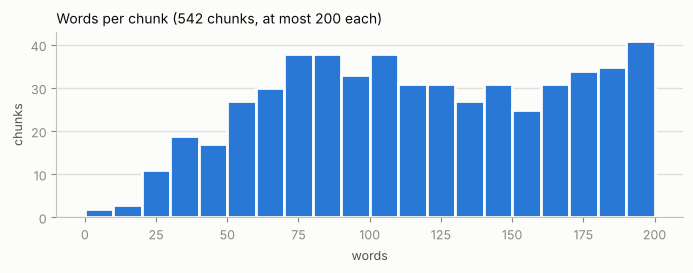

In [11]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(chunks["words"], bins=range(0, 210, 10), color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.set_title(f"Words per chunk ({len(chunks)} chunks, at most 200 each)", loc="left")
ax.set_xlabel("words")
ax.set_ylabel("chunks")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Some chunk ids and the citations they produce:

In [12]:
examples = [
    "gpsr/19",
    "gpsr/16/1",
    "ucpd/5/1-2",
    "textile/annex_v/1-29",
    "ucpd/annex_i/4c-5",
    "light_sources/annex_v/1#2",
    "pangv/4/1-2",
    "pid_guidance/2.1#2",
    "aldi_sued/29",
    "aldi_sued/operative_part",
]
chunks.set_index("chunk_id").loc[examples, ["citation", "words"]]

,citation,words
chunk_id,,
gpsr/19,GPSR Art. 19,174
gpsr/16/1,GPSR Art. 16(1),87
ucpd/5/1-2,UCPD Art. 5(1)–(2),77
textile/annex_v/1-29,"Regulation (EU) No 1007/2011 Annex V, points 1–29",193
ucpd/annex_i/4c-5,"UCPD Annex I, points 4c–5",108
light_sources/annex_v/1#2,"Regulation (EU) 2019/2015 Annex V, point 1",189
pangv/4/1-2,PAngV § 4(1)–(2),94
pid_guidance/2.1#2,"Commission guidance on Article 6a, section 2.1",182
aldi_sued/29,"Case C-330/23 (Aldi Süd), para. 29",83


A chunk id is `law/article/paragraphs`, with `#2`, `#3` for the parts of a paragraph
that had to be cut. `ucpd/5/1-2` holds two short paragraphs, cited "Art. 5(1)–(2)".

## 4. Three ways to search

**Keyword search** uses Postgres full-text search: each chunk's words are cut to their
stems ("prices" → "price") with English or German rules, matching the law's language.
Results are ranked with **BM25**, where a word counts more when few chunks contain it.
Postgres's own ranking (`ts_rank`) ignores how rare a word is, so "price", which is in
hundreds of chunks, counted as much as "rayon".

Keyword search is good at exact, rare words:

In [13]:
hits_table(keyword_search(conn, "cashgora", k=3))

,citation,score,starts with
0,Regulation (EU) No 1007/2011 Annex I,6.665,(referred to in Article 5)\nTable 1\nNumber | Name | Fibre description\n1 | wool | fibre from


In [14]:
hits_table(keyword_search(conn, "Grundpreis Fertigpackungen", k=3))

,citation,score,starts with
0,PAngV § 4(1)–(2),13.421,"(1) Wer als Unternehmer Verbrauchern Waren in Fertigpackungen, offenen Packungen oder als"
1,PAngV § 2,10.408,Im Sinne dieser Verordnung bedeutet\n1. „Arbeits- oder Mengenpreis“ den verbrauchsabhängige
2,PAngV § 5,7.957,"(1) Die Mengeneinheit für den Grundpreis ist jeweils 1 Kilogramm, 1 Liter, 1 Kubikmeter, 1"


**Meaning search** compares 384-dimensional embeddings from the
`multilingual-e5-small` model, which runs locally on CPU. Texts with similar meanings
get similar vectors, whatever words they use, so a question about "carbon offsets" finds
the rule about "offsetting of greenhouse gas emissions":

In [15]:
hits_table(
    search(
        conn,
        "Can a seller call a product climate neutral because of carbon offsets?",
        "meaning",
        k=3,
        embedder=embedder,
    )
)

,citation,score,starts with
0,"UCPD Annex I, points 4c–5",0.869,"4c. Claiming, based on the offsetting of greenhouse gas emissions, that a product has a ne"
1,"Commission guidance on Article 6a, section 2.1",0.835,Where a trader sells goods through different sales channels/points of sale (e.g. different
2,UCPD Art. 7(6)–(7),0.834,"6. Where a trader provides access to consumer reviews of products, information about wheth"


The model knows about 100 languages, so a German question finds an English article:

In [16]:
hits_table(
    search(
        conn,
        "Welche Angaben zum Hersteller muss ein Online-Angebot enthalten?",
        "meaning",
        k=3,
        laws=["gpsr"],
        embedder=embedder,
    )
)

,citation,score,starts with
0,GPSR Art. 19,0.828,Where economic operators make products available on the market online or through other mea
1,GPSR Art. 22(9),0.827,9. For the purpose of compliance with the requirements of Article 31(1) and (2) of Regulat
2,GPSR Art. 22(9),0.822,"(b) where the manufacturer is not established in the Union, the name, postal and electroni"


**Hybrid search** runs both and merges the two rankings with Reciprocal Rank Fusion
(RRF): every chunk scores 1 / (60 + its rank) in each list it appears in, and the
scores are added up. Here is how one question is merged:

In [17]:
question = "Must a product listing include a picture of the product?"
by_keyword = [h.chunk_id for h in keyword_search(conn, question, k=30)]
by_meaning = [h.chunk_id for h in meaning_search(conn, embedder.query(question), k=30)]
fused = search(conn, question, "hybrid", k=5, embedder=embedder)


def rank_in(ranking, chunk_id):
    return ranking.index(chunk_id) + 1 if chunk_id in ranking else None


pd.DataFrame(
    [
        {
            "citation": h.citation,
            "keyword rank": rank_in(by_keyword, h.chunk_id),
            "meaning rank": rank_in(by_meaning, h.chunk_id),
            "RRF score": round(h.score, 4),
        }
        for h in fused
    ]
).astype({"keyword rank": "Int64", "meaning rank": "Int64"})

,citation,keyword rank,meaning rank,RRF score
0,GPSR Art. 22(9),2,2,0.0323
1,Directive 98/6/EC Art. 5,23,4,0.0277
2,GPSR Art. 19,3,29,0.0271
3,GPSR Art. 9(2),20,17,0.0255
4,GPSR Art. 36(2),1,<NA>,0.0164


A chunk needs both lists to win. GPSR Art. 22(9), 2nd in both, comes first. GPSR
Art. 36(2), 1st by keyword but missing from the meaning list, drops to 5th. GPSR
Art. 19, the right answer ("including a picture of it"), is 3rd by keyword but only
29th by meaning, and ends up 3rd.

## 5. How good is each method?

`rulebook/questions.yaml` holds 31 test questions, written in everyday words (three in
German) before any search was run, each with the articles that answer it. For every
question and method, the first ten results are scored:

- **hit@1**: the first result is from a right article
- **hit@5**: a right article is among the first five (the agent reads five)
- **MRR**: the average of 1 / rank of the first right result (0 if none in the first
  ten); 1.0 is perfect, 0.5 means "second on average"

In [18]:
results = run(conn, embedder)
table = scores(results)
table

,hit_at_1,hit_at_5,mrr
method,,,
keyword,0.29,0.45,0.37
meaning,0.55,0.84,0.65
hybrid,0.42,0.68,0.51


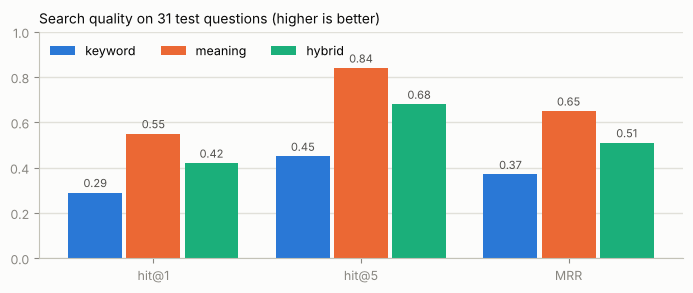

In [19]:
fig, ax = plt.subplots(figsize=(7, 3))
metrics = ["hit_at_1", "hit_at_5", "mrr"]
labels = {"hit_at_1": "hit@1", "hit_at_5": "hit@5", "mrr": "MRR"}
colours = {"keyword": BLUE, "meaning": ORANGE, "hybrid": AQUA}
width = 0.26
for i, method in enumerate(table.index):
    xs = [m + (i - 1) * (width + 0.02) for m in range(len(metrics))]
    bars = ax.bar(xs, table.loc[method, metrics], width, color=colours[method], label=method)
    ax.bar_label(
        bars,
        labels=[f"{v:.2f}" for v in table.loc[method, metrics]],
        padding=2,
        color=SECONDARY,
        fontsize=8,
    )
ax.set_xticks(range(len(metrics)), [labels[m] for m in metrics])
ax.grid(axis="x", visible=False)
ax.set_ylim(0, 1)
ax.set_title("Search quality on 31 test questions (higher is better)", loc="left")
ax.legend(frameon=False, loc="upper left", ncols=3)
plt.tight_layout()
plt.show()

**Meaning search wins**, and hybrid search does worse than meaning search alone. The
test questions use everyday words ("was price", "price per kilo", "company based in
the EU") while the laws use legal ones ("prior price", "unit price", "economic operator
established in the Union"). So keyword search often ranks the wrong chunks first, and
RRF gives its list as much weight as the good one. That is why meaning search is the
default in `search()`; hybrid stays available for exact terms such as fibre names or
German legal words.

The first right result for each question (empty: not in the first ten):

In [20]:
ranks = results.pivot(index="question", columns="method", values="rank")
ranks[["keyword", "meaning", "hybrid"]].astype("Int64").sort_values("meaning")

method,keyword,meaning,hybrid
question,,,
"Can a seller call a product ""climate neutral"" because of carbon offsets?",1,1,1
Can a seller put the price up for a week and then advertise a big discount?,1,1,1
"Can a seller write ""rayon"" instead of the official EU fibre name?",2,1,1
Do I need to show the earlier price for food reduced because it will soon go off?,<NA>,1,<NA>
Does the 30-day rule apply when I compare my price with the manufacturer's recommended retail price?,1,1,1
Is a product photo in a different colour from the description misleading?,8,1,2
How many days back do I look to find the lowest price before a discount?,<NA>,1,6
How do I label a fabric made of several different fibres?,8,1,8
"Must a ""-30%"" badge be worked out from the lowest price of the last 30 days?",9,1,8


### Postgres ranking or BM25?

An earlier version ranked keyword results with Postgres's `ts_rank_cd`. The same
evaluation, with that ranking:

In [21]:
TS_RANK_SQL = """
    WITH q AS (
        SELECT replace(plainto_tsquery('english', %(query)s)::text, '&', '|')::tsquery AS en,
               replace(plainto_tsquery('german', %(query)s)::text, '&', '|')::tsquery AS de
    )
    SELECT chunk_id
    FROM rulebook.chunks c, q
    WHERE c.search_words @@ CASE c.language WHEN 'de' THEN q.de ELSE q.en END
    ORDER BY ts_rank_cd(c.search_words, CASE c.language WHEN 'de' THEN q.de ELSE q.en END) DESC,
             chunk_id
    LIMIT 10
"""


class Found:  # first_right_rank only needs a chunk_id
    def __init__(self, chunk_id):
        self.chunk_id = chunk_id


rows = []
for q in load_questions():
    found = [Found(r[0]) for r in conn.execute(TS_RANK_SQL, {"query": q.question}).fetchall()]
    rank = first_right_rank(found, q.answers)
    rows.append({"question": q.question, "method": "keyword (ts_rank)", "rank": rank})
bm25 = table.loc[["keyword"]].rename(index={"keyword": "keyword (BM25)"})
pd.concat([scores(pd.DataFrame(rows)), bm25])

,hit_at_1,hit_at_5,mrr
method,,,
keyword (ts_rank),0.16,0.29,0.23
keyword (BM25),0.29,0.45,0.37


BM25 almost doubles hit@1. It still trails meaning search on these questions, because
it can only find words that are actually in the law.

### What the misses show

- **The answer key is strict.** "Can I leave out the price per litre when the bottle
  holds exactly one litre?" lists only PAngV § 4, but Directive 98/6/EC Art. 3(1) says
  the same in English, and meaning search ranks it second. Such results count as
  misses: the key was written before the search and was not changed afterwards.
- **Language pull.** English questions tend to find English texts first, and German
  ones German texts, even when the answer is in the other language.
- **A small model.** "Which company has to be based in the EU?" never reaches
  GPSR Art. 16(1) ("an economic operator established in the Union"). A bigger
  embedding model would likely do better, at the cost of speed and memory.

## 6. The agent's login can read the rulebook, not change it

In [22]:
with connect_as_agent() as agent:
    count = agent.execute("SELECT count(*) FROM rulebook.chunks").fetchone()[0]
    print("chunks the agent can read:", count)
    try:
        agent.execute("DELETE FROM rulebook.chunks")
    except psycopg.errors.InsufficientPrivilege as error:
        print("delete refused:", error.diag.message_primary)

chunks the agent can read: 542
delete refused: permission denied for table chunks


In [23]:
conn.close()